# FedEx Logistics – Supply Chain Delivery History Analysis

**Project Type:** Exploratory Data Analysis (EDA)  
**Contribution:** Individual  
**Dataset:** SCMS Delivery History Dataset

## Project Summary
This project explores historical supply-chain delivery records to understand shipment performance, delivery delays, freight-cost patterns, vendor and country-level variation, and product mix. The goal is to turn the available records into evidence-based operational insights.

> **Important:** This notebook distinguishes observed data from assumptions. Missing or non-numeric values are not silently treated as zero. Findings and recommendations must be based on the outputs generated from the supplied dataset.

## 1. Problem Statement

Supply-chain operations depend on coordinating purchase orders, vendors, shipment modes, delivery schedules, and destination countries. Delays and logistics costs can affect service reliability and operational efficiency.

### Business objectives
1. Measure delivery performance against scheduled delivery dates.
2. Identify countries, shipment modes, product groups, and vendors associated with longer delivery delays.
3. Examine freight-cost and shipment-weight patterns where numeric values are available.
4. Understand missing, uncaptured, and inconsistent fields that limit analysis.
5. Present practical, data-supported recommendations for supply-chain stakeholders.

### Key questions
- What proportion of records can be evaluated for delivery timeliness?
- How many deliveries were early, on time, or late?
- Which shipment modes and destination countries show different delay patterns?
- How do freight costs vary across shipment modes and product groups?
- Which data-quality limitations should be addressed before operational decisions are made?

## 2. General Guidelines and Analysis Approach
- Keep code readable, modular, and commented.
- Explain why each cleaning decision is made.
- Do not replace missing freight cost or weight with zero.
- Treat text such as `Invoiced Separately`, `Freight Included in Commodity Cost`, and `Weight Captured Separately` as non-numeric business labels, not numeric measurements.
- Use only valid scheduled and delivered dates to calculate delivery delay.
- Include a short interpretation after each major visualization.
- Run the notebook from top to bottom after uploading the CSV file.

## 3. Know Your Data

### 3.1 Import Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

### 3.2 Load Dataset
Upload `SCMS_Delivery_History_Dataset.csv` to the Colab session, or update the path below.

https://drive.google.com/file/d/1G3sg45qaljQ9w-bB5i4-n7QAM59cR4xN/view

In [ ]:
from pathlib import Path

DATA_PATH = Path("SCMS_Delivery_History_Dataset.csv")

if not DATA_PATH.exists():
    # Google Colab upload fallback
    try:
        from google.colab import files
        uploaded = files.upload()
        uploaded_name = next(iter(uploaded))
        DATA_PATH = Path(uploaded_name)
    except Exception as exc:
        raise FileNotFoundError(
            "Dataset not found. Upload SCMS_Delivery_History_Dataset.csv "
            "or set DATA_PATH to its location."
        ) from exc

df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded successfully: {df.shape[0]:,} rows and {df.shape[1]} columns")
display(df.head())

Saving SCMS_Delivery_History_Dataset.csv to SCMS_Delivery_History_Dataset.csv
Dataset loaded successfully: 10,324 rows and 33 columns


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 Tests","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 240 ml",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LABORATORIES LIMITED),"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


### 3.3 Dataset First View

In [ ]:
display(df.head(10))
display(df.sample(min(5, len(df)), random_state=42))

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 Tests","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 240 ml",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.00,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.00,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LABORATORIES LIMITED),"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.80,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.00,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN
5,23,112-NG-T01,Pre-PQ Process,SCMS-87,ASN-57,Nigeria,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,28-Sep-06,28-Sep-06,28-Sep-06,ARV,Pediatric,Aurobindo Pharma Limited,"Zidovudine 10mg/ml, oral solution, Bottle, 240 ml",Zidovudine,Generic,10mg/ml,Oral solution,240,416,2225.60,5.35,0.02,"Aurobindo Unit III, India",Yes,504,5920.42,NaN
6,44,110-ZM-T01,Pre-PQ Process,SCMS-139,ASN-130,Zambia,PMO - US,Direct Drop,DDU,Air,Pre-PQ Process,Date Not Captured,8-Jan-07,8-Jan-07,8-Jan-07,ARV,Pediatric,MERCK SHARP & DOHME IDEA GMBH (FORMALLY MERCK SHARP & DOHME B.V.),"Efavirenz 200mg [Stocrin/Sustiva], capsule, 90 Caps",Efavirenz,Stocrin/Sustiva,200mg,Capsule,90,135,4374.00,32.40,0.36,MSD South Granville Australia,Yes,328,Freight Included in Commodity Cost,NaN
7,45,109-TZ-T01,Pre-PQ Process,SCMS-140,ASN-94,Tanzania,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,24-Nov-06,24-Nov-06,24-Nov-06,ARV,Adult,Aurobindo Pharma Limited,"Nevirapine 200mg, tablets, 60 Tabs",Nevirapine,Generic,200mg,Tablet,60,16667,60834.55,3.65,0.06,"Aurobindo Unit III, India",Yes,1478,6212.41,NaN
8,46,112-NG-T01,Pre-PQ Process,SCMS-156,ASN-93,Nigeria,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,7-Dec-06,7-Dec-06,7-Dec-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,273,532.35,1.95,0.03,"Aurobindo Unit III, India",No,See ASN-93 (ID#:1281),See ASN-93 (ID#:1281),NaN
9,47,110-ZM-T01,Pre-PQ Process,SCMS-165,ASN-199,Zambia,PMO - US,Direct Drop,CIP,Air,Pre-PQ Process,11/13/06,30-Jan-07,30-Jan-07,30-Jan-07,ARV,Adult,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),"Lopinavir/Ritonavir 200/50mg [Aluvi

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
6584,82275,110-ZM-T30,FPQ-4035,SO-34340,DN-1515,Zambia,PMO - US,From RDC,N/A - From RDC,Truck,8/5/09,N/A - From RDC,30-Nov-09,23-Nov-09,23-Nov-09,ARV,Adult,SCMS from RDC,"Efavirenz 600mg, tablets, 30 Tabs",Efavirenz,Generic,600mg,Tablet,30,47227,272972.06,5.78,0.19,"Aurobindo Unit III, India",Yes,4959,9973.51,535.03
1692,11520,117-ET-T01,Pre-PQ Process,SO-1512,DN-517,Ethiopia,PMO - US,From RDC,N/A - From RDC,Air,Pre-PQ Process,N/A - From RDC,14-Dec-07,14-Dec-07,14-Dec-07,ARV,Adult,SCMS from RDC,"Tenofovir Disoproxil Fumarate 300mg [Viread], tablets, 30 Tabs",Tenofovir Disoproxil Fumarate,Viread,300mg,Tablet,30,535,9095.00,17.00,0.57,Gilead(Nycomed) Oranienburg DE,Yes,33,755.5,14.55
2692,13064,116-ZA-T30,FPQ-14942,SCMS-259075,ASN-32122,South Africa,PMO - US,Direct Drop,DDP,Truck,9/11/14,5/11/15,12-May-15,12-May-15,12-May-15,ARV,Adult,PHARMACY DIRECT,"Abacavir 300mg, tablets, 60 Tabs",Abacavir,Generic,300mg,Tablet,60,25,1246.30,49.85,0.83,"Aurobindo Unit III, India",Yes,Weight Captured Separately,Freight Included in Commodity Cost,1.28
7702,83607,151-NG-T30,FPQ-9432,SO-42803,DN-2769,Nigeria,PMO - US,From RDC,N/A - From RDC,Air Charter,3/1/12,N/A - From RDC,2-Aug-12,24-Jul-12,24-Jul-12,ARV,Adult,SCMS from RDC,"Lamivudine/Tenofovir Disoproxil Fumarate 300/300mg, tablets, 30 Tabs",Lamivudine/Tenofovir Disoproxil Fumarate,Generic,300/300mg,Tablet - FDC,30,1161,6431.94,5.54,0.18,"Cipla, Kurkumbh, India",Yes,2566,16532.5,9.02
321,3039,111-MZ-T01,Pre-PQ Process,SCMS-18060,ASN-1651,Mozambique,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,2/25/08,13-Jun-08,13-Jun-08,13-Jun-08,HRDT,HIV test - Ancillary,"Orgenics, Ltd","HIV, Lancet, Safety, for HIV Test kits, 100 Pcs","HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",Generic,NaN,Test kit - Ancillary,100,4200,42.00,0.01,0.00,Inverness Japan,Yes,Weight Captured Separately,Invoiced Separately,0.07


### 3.4 Rows, Columns, and Data Types

In [ ]:
print("Shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types and non-null counts:")
df.info()

Shape: (10324, 33)
\nColumn names:
['ID', 'Project Code', 'PQ #', 'PO / SO #', 'ASN/DN #', 'Country', 'Managed By', 'Fulfill Via', 'Vendor INCO Term', 'Shipment Mode', 'PQ First Sent to Client Date', 'PO Sent to Vendor Date', 'Scheduled Delivery Date', 'Delivered to Client Date', 'Delivery Recorded Date', 'Product Group', 'Sub Classification', 'Vendor', 'Item Description', 'Molecule/Test Type', 'Brand', 'Dosage', 'Dosage Form', 'Unit of Measure (Per Pack)', 'Line Item Quantity', 'Line Item Value', 'Pack Price', 'Unit Price', 'Manufacturing Site', 'First Line Designation', 'Weight (Kilograms)', 'Freight Cost (USD)', 'Line Item Insurance (USD)']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code           

### 3.5 Statistical Summary

In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,10324.0,NaN,NaN,NaN,51098.968229,31944.332496,1.0,12795.75,57540.5,83648.25,86823.0
Project Code,10324,142,116-ZA-T30,768,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PQ #,10324,1237,Pre-PQ Process,2681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PO / SO #,10324,6233,SCMS-199289,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ASN/DN #,10324,7030,ASN-19166,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,10324,43,South Africa,1406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Managed By,10324,4,PMO - US,10265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fulfill Via,10324,2,From RDC,5404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vendor INCO Term,10324,8,N/A - From RDC,5404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shipment Mode,9964,4,Air,6113,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.6 Initial Observations

In [ ]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Countries represented: {df['Country'].nunique(dropna=True)}")
print(f"Product groups represented: {df['Product Group'].nunique(dropna=True)}")
print(f"Shipment modes represented (excluding missing): {df['Shipment Mode'].nunique(dropna=True)}")

Rows: 10,324
Columns: 33
Exact duplicate rows: 0
Countries represented: 43
Product groups represented: 5
Shipment modes represented (excluding missing): 4


**Interpretation prompt:** After running the cells above, describe the dataset size, the main operational entities represented, and any immediate data-quality concerns. Do not infer delivery performance until the date fields have been parsed and validated.

## 4. Understanding Variables

In [ ]:
column_reference = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Missing Count": df.isna().sum().values,
    "Unique Values": [df[c].nunique(dropna=True) for c in df.columns]
})
display(column_reference)

,Column,Data Type,Non-Null Count,Missing Count,Unique Values
0,ID,int64,10324,0,10324
1,Project Code,object,10324,0,142
2,PQ #,object,10324,0,1237
3,PO / SO #,object,10324,0,6233
4,ASN/DN #,object,10324,0,7030
5,Country,object,10324,0,43
6,Managed By,object,10324,0,4
7,Fulfill Via,object,10324,0,2
8,Vendor INCO Term,object,10324,0,8
9,Shipment Mode,object,9964,360,4


### Variable groups
- **Identifiers:** `ID`, `Project Code`, `PQ #`, `PO / SO #`, `ASN/DN #`
- **Geography and operations:** `Country`, `Managed By`, `Fulfill Via`, `Shipment Mode`
- **Dates:** purchase request, vendor order, scheduled delivery, delivered date, and recorded date
- **Product information:** `Product Group`, `Sub Classification`, `Item Description`, `Molecule/Test Type`, `Brand`, `Dosage`, `Dosage Form`
- **Commercial and logistics measures:** `Line Item Quantity`, `Line Item Value`, `Pack Price`, `Unit Price`, `Weight (Kilograms)`, `Freight Cost (USD)`, `Line Item Insurance (USD)`

## 5. Data Cleaning and Preparation

### 5.1 Work on a copy and standardize text

In [ ]:
data = df.copy()

# Strip leading/trailing whitespace from text columns while preserving missing values.
text_cols = data.select_dtypes(include="object").columns
for col in text_cols:
    data[col] = data[col].map(lambda x: x.strip() if isinstance(x, str) else x)

print("Working copy created:", data.shape)

Working copy created: (10324, 33)


### 5.2 Duplicate check

In [ ]:
duplicate_count = data.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

# Remove only exact duplicate rows, if any. No business-key duplicates are removed
# because the dataset documentation does not define a unique composite key.
data = data.drop_duplicates().copy()
print("Shape after exact-duplicate check:", data.shape)

Exact duplicate rows: 0
Shape after exact-duplicate check: (10324, 33)


### 5.3 Missing values

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": data.isna().sum(),
    "Missing Percent": (data.isna().mean() * 100).round(2)
}).sort_values("Missing Percent", ascending=False)
display(missing_summary[missing_summary["Missing Count"] > 0])

,Missing Count,Missing Percent
Dosage,1736,16.82
Shipment Mode,360,3.49
Line Item Insurance (USD),287,2.78


**Missing-value treatment rationale**
- Categorical fields: retain missing values as missing; for plots, pandas naturally excludes null groups unless explicitly labeled.
- `Dosage`: do not invent dosage information; retain nulls.
- `Shipment Mode`: retain nulls and report their count; exclude from mode comparisons.
- `Line Item Insurance (USD)`: retain nulls; do not interpret missing insurance as zero.
- Text-coded logistics fields are handled separately below; labels are not missing numeric values.

### 5.4 Parse date fields

In [ ]:
date_cols = [
    "PQ First Sent to Client Date",
    "PO Sent to Vendor Date",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "Delivery Recorded Date"
]

# Coerce non-date placeholders (e.g., 'Date Not Captured', 'N/A - From RDC',
# and 'Pre-PQ Process') to NaT instead of treating them as dates.
for col in date_cols:
    data[col + " Parsed"] = pd.to_datetime(data[col], errors="coerce", dayfirst=True)

date_quality = pd.DataFrame({
    "Original Non-null": data[date_cols].notna().sum(),
    "Parsed Valid Dates": data[[c + " Parsed" for c in date_cols]].notna().sum().values,
    "Unparsed / Placeholder": [
        (data[c].notna() & data[c + " Parsed"].isna()).sum() for c in date_cols
    ]
}, index=date_cols)
display(date_quality)

,Original Non-null,Parsed Valid Dates,Unparsed / Placeholder
PQ First Sent to Client Date,10324,7643,2681
PO Sent to Vendor Date,10324,4592,5732
Scheduled Delivery Date,10324,10324,0
Delivered to Client Date,10324,10324,0
Delivery Recorded Date,10324,10324,0


### 5.5 Convert weight and freight cost carefully

In [ ]:
def extract_numeric(series):
    """Extract a numeric value; descriptive labels become NaN."""
    cleaned = series.astype("string").str.replace(",", "", regex=False)
    extracted = cleaned.str.extract(r"([-+]?[0-9]*\.?[0-9]+)", expand=False)
    return pd.to_numeric(extracted, errors="coerce")

data["Weight_kg_numeric"] = extract_numeric(data["Weight (Kilograms)"])
data["Freight_Cost_USD_numeric"] = extract_numeric(data["Freight Cost (USD)"])

print("Weight numeric values:", data["Weight_kg_numeric"].notna().sum())
print("Freight numeric values:", data["Freight_Cost_USD_numeric"].notna().sum())
print("\nFreight text labels:")
display(data.loc[data["Freight_Cost_USD_numeric"].isna(), "Freight Cost (USD)"].value_counts().head(10))
print("\nWeight text labels:")
display(data.loc[data["Weight_kg_numeric"].isna(), "Weight (Kilograms)"].value_counts().head(10))

Weight numeric values: 8817
Freight numeric values: 8643

Freight text labels:


,count
Freight Cost (USD),
Freight Included in Commodity Cost,1442
Invoiced Separately,239



Weight text labels:


,count
Weight (Kilograms),
Weight Captured Separately,1507


### 5.6 Create delivery-performance features

In [ ]:
data["Delivery_Delay_Days"] = (
    data["Delivered to Client Date Parsed"] - data["Scheduled Delivery Date Parsed"]
).dt.days

# Classify only rows with both valid dates.
data["Delivery_Status"] = np.select(
    [
        data["Delivery_Delay_Days"].lt(0),
        data["Delivery_Delay_Days"].eq(0),
        data["Delivery_Delay_Days"].gt(0)
    ],
    ["Early", "On Time", "Late"],
    default="Not Evaluated"
)

data["Freight_to_Line_Value_Ratio"] = (
    data["Freight_Cost_USD_numeric"] / data["Line Item Value"].replace(0, np.nan)
)

print("Rows with evaluable delivery delay:", data["Delivery_Delay_Days"].notna().sum())
display(data["Delivery_Status"].value_counts(dropna=False).to_frame("Records"))

Rows with evaluable delivery delay: 10324


,Records
Delivery_Status,
On Time,6324
Early,2814
Late,1186


### 5.7 Cleaning summary

In [ ]:
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Rows after exact duplicate check",
        "Rows with valid scheduled date",
        "Rows with valid delivered date",
        "Rows with both dates (delay evaluable)",
        "Rows with numeric freight cost",
        "Rows with numeric weight"
    ],
    "Count": [
        len(data),
        data["Scheduled Delivery Date Parsed"].notna().sum(),
        data["Delivered to Client Date Parsed"].notna().sum(),
        data["Delivery_Delay_Days"].notna().sum(),
        data["Freight_Cost_USD_numeric"].notna().sum(),
        data["Weight_kg_numeric"].notna().sum()
    ]
})
display(cleaning_summary)

,Metric,Count
0,Rows after exact duplicate check,10324
1,Rows with valid scheduled date,10324
2,Rows with valid delivered date,10324
3,Rows with both dates (delay evaluable),10324
4,Rows with numeric freight cost,8643
5,Rows with numeric weight,8817


## 6. Hypotheses and Assumptions

These are questions to test, not conclusions:
1. Delivery delay may differ by shipment mode.
2. Delivery delay may vary by destination country.
3. Freight cost may differ across shipment modes and product groups.
4. Shipment weight and freight cost may be positively associated among records with numeric values.
5. Records fulfilled through a Regional Distribution Centre (RDC) may have a different delivery profile from Direct Drop records.

**Assumptions and limitations:** The dataset is historical and observational. It does not, by itself, establish causation. Comparisons should include group sizes and the number of records excluded because dates or numeric measures were unavailable.

## 7. Exploratory Data Analysis (EDA)

### 7.1 Univariate analysis – shipment mode

,Shipment Records
Shipment Mode,
Air,6113
Truck,2830
Air Charter,650
Ocean,371
Missing,360


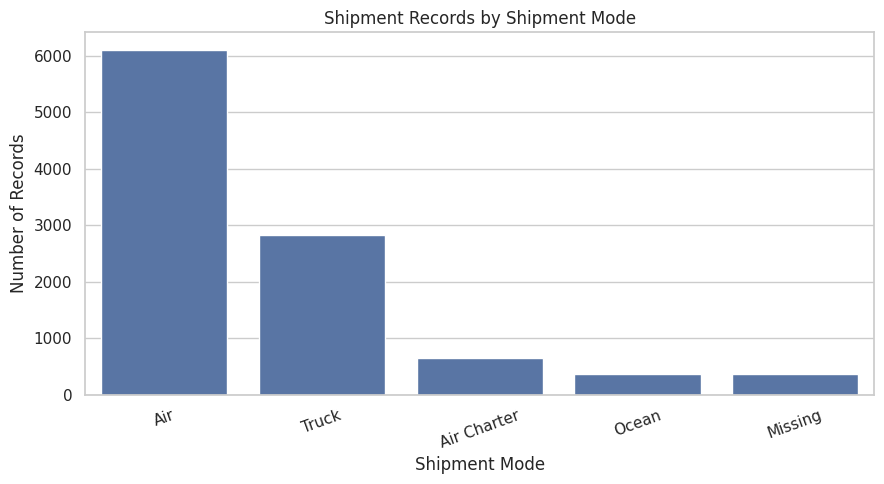

In [ ]:
mode_counts = data["Shipment Mode"].fillna("Missing").value_counts()
display(mode_counts.to_frame("Shipment Records"))
plt.figure(figsize=(9, 5))
sns.barplot(x=mode_counts.index, y=mode_counts.values)
plt.title("Shipment Records by Shipment Mode")
plt.xlabel("Shipment Mode")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Why this chart?** A bar chart compares counts across discrete shipment categories.  
**What to observe:** The dominant shipment mode and the share of records with missing mode.  
**Business relevance:** Shipment volume by mode helps frame where operational performance reviews may have the largest coverage.

**Interpretation – Shipment Mode Distribution**

- Air was the most frequently used shipment mode, accounting for 6,113 records (59.21%).
- Truck accounted for 2,830 records (27.41%).
- Air Charter represented 650 records (6.30%), while Ocean accounted for 371 records (3.59%).
- Shipment mode information was missing in 360 records (3.49%).

**Business Insight:** Air and Truck together represented the majority of shipments. Logistics planning should focus on these two modes while improving the completeness of shipment-mode records.

### 7.2 Product group distribution

,Shipment Records
Product Group,
ARV,8550
HRDT,1728
ANTM,22
ACT,16
MRDT,8


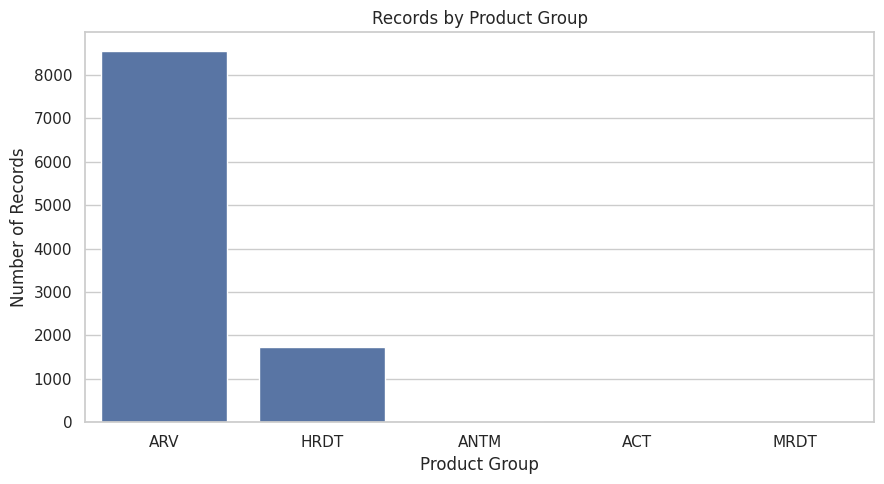

In [ ]:
product_counts = data["Product Group"].value_counts()
display(product_counts.to_frame("Shipment Records"))
plt.figure(figsize=(9, 5))
sns.barplot(x=product_counts.index, y=product_counts.values)
plt.title("Records by Product Group")
plt.xlabel("Product Group")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

**Why this chart?** Product groups are categorical; a bar chart makes their relative volumes easy to compare.  
**What to observe:** Whether records are concentrated in a small number of product groups.  
**Business relevance:** Product mix provides context when comparing delivery and cost metrics.

**Interpretation – Product Group Distribution**

- ARV was the largest product group with 8,550 records (82.82%).
- HRDT was the second-largest group with 1,728 records (16.74%).
- ANTM, ACT, and MRDT together represented a very small proportion of the dataset.

**Business Insight:** The dataset is heavily concentrated in ARV and HRDT products. Operational planning and inventory monitoring should consider this product distribution. Comparisons involving smaller groups should be interpreted cautiously because of their limited record counts.

### 7.3 Delivery status distribution

,Records
Delivery_Status,
Early,2814
On Time,6324
Late,1186
Not Evaluated,0


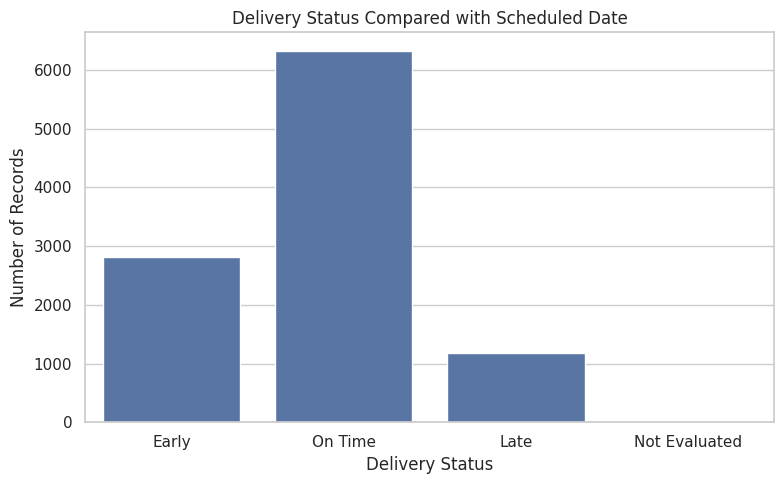

In [ ]:
status_order = ["Early", "On Time", "Late", "Not Evaluated"]
status_counts = data["Delivery_Status"].value_counts().reindex(status_order, fill_value=0)
display(status_counts.to_frame("Records"))
plt.figure(figsize=(8, 5))
sns.barplot(x=status_counts.index, y=status_counts.values)
plt.title("Delivery Status Compared with Scheduled Date")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

**Why this chart?** Delivery status is a small set of categories, so a bar chart clearly compares early, on-time, late, and unevaluable records.  
**What to observe:** The proportion of records that can actually be assessed and the split among evaluated deliveries.  
**Business relevance:** This is a direct service-performance measure, but it must be reported with its evaluation coverage.

**Interpretation – Delivery Status Distribution**

- 6,324 shipments (61.26%) were delivered on time.
- 2,814 shipments (27.26%) were delivered early.
- 1,186 shipments (11.49%) were delivered late.
- All 10,324 records were evaluated for delivery status.

**Business Insight:** Most shipments were delivered on or before their scheduled dates. However, 1,186 late deliveries represent an opportunity to investigate operational issues and improve delivery reliability.

### 7.4 Distribution of delivery delay

,Delivery Delay (Days)
count,10324.000000
mean,-6.023537
std,27.233640
min,-372.000000
25%,-3.000000
50%,0.000000
75%,0.000000
max,192.000000


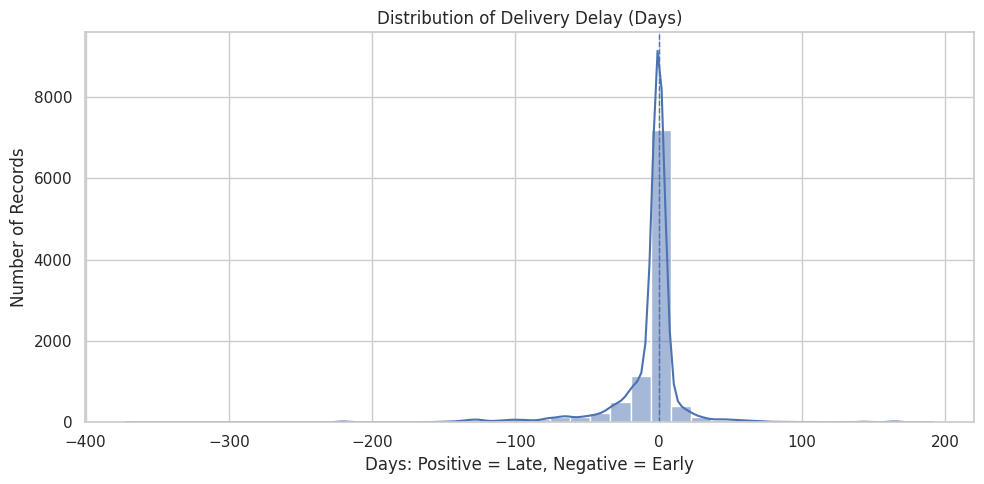

In [ ]:
delay = data["Delivery_Delay_Days"].dropna()
display(delay.describe().to_frame("Delivery Delay (Days)"))
if len(delay):
    plt.figure(figsize=(10, 5))
    sns.histplot(delay, bins=40, kde=True)
    plt.axvline(0, linestyle="--", linewidth=1)
    plt.title("Distribution of Delivery Delay (Days)")
    plt.xlabel("Days: Positive = Late, Negative = Early")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()
else:
    print("No valid delivery-delay observations available.")

**Why this chart?** A histogram shows the distribution, spread, skewness, and potential extreme delays.  
**What to observe:** Whether delays cluster around zero, whether the distribution is skewed, and whether unusually large values exist.  
**Business relevance:** The distribution helps distinguish typical delivery variation from extreme cases requiring investigation.

**Interpretation – Distribution of Delivery Delay**

- The average delivery delay was approximately -6.02 days.
- The median delivery delay was 0 days.
- The minimum recorded delay was -372 days, while the maximum was 192 days.
- The middle 50% of observations ranged from -3 to 0 days.

**Business Insight:** The median indicates that at least half of the shipments were delivered on or before their scheduled dates. However, extreme early and late records affect the average, so both mean and median should be considered when evaluating delivery performance.

### 7.5 Delay by shipment mode

,Records,Mean_Delay,Median_Delay
Shipment Mode,,,
Air Charter,650,-19.04,-13.0
Air,6113,-3.76,0.0
Ocean,371,5.87,0.0
Truck,2830,-9.92,0.0


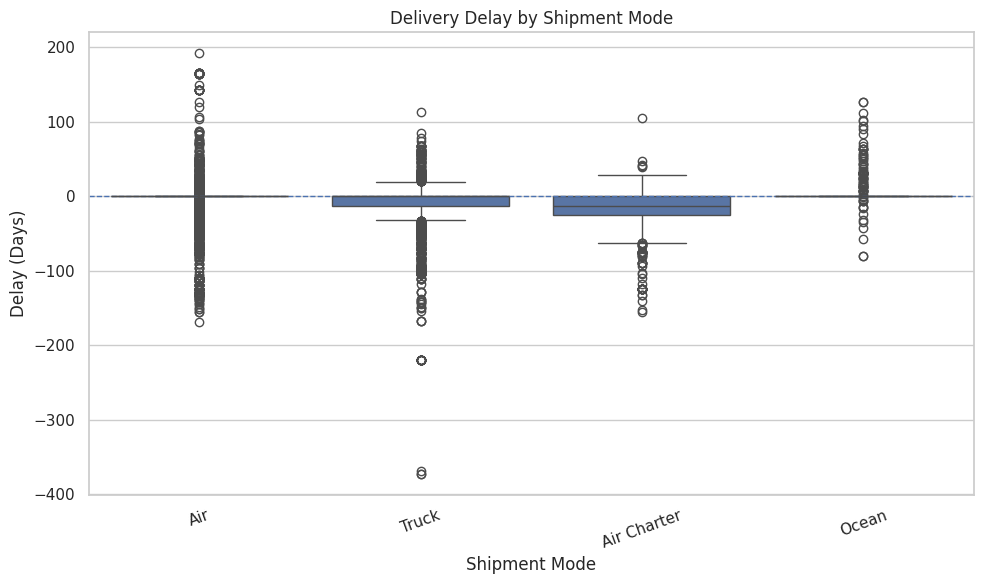

In [ ]:
delay_by_mode = data.dropna(subset=["Delivery_Delay_Days", "Shipment Mode"]).copy()
mode_delay_summary = delay_by_mode.groupby("Shipment Mode")["Delivery_Delay_Days"].agg(
    Records="count", Mean_Delay="mean", Median_Delay="median"
).sort_values("Median_Delay")
display(mode_delay_summary.round(2))
if not delay_by_mode.empty:
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=delay_by_mode, x="Shipment Mode", y="Delivery_Delay_Days")
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.title("Delivery Delay by Shipment Mode")
    plt.xlabel("Shipment Mode")
    plt.ylabel("Delay (Days)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

**Why this chart?** Box plots compare medians, spread, and outliers across shipment modes.  
**What to observe:** Differences in median delay and variability; also check sample counts before interpreting small groups.  
**Business relevance:** The results can help identify shipment modes that warrant a closer service-level review. Association does not prove that the mode caused the delay.

**Interpretation – Delivery Delay by Shipment Mode**

- Air Charter had an average delay of -19.04 days and a median delay of -13 days.
- Air had an average delay of -3.76 days and a median of 0 days.
- Ocean showed a positive average delay of 5.87 days and a median of 0 days.
- Truck had an average delay of -9.92 days and a median of 0 days.

**Business Insight:** Ocean shipments showed a positive average delay, making them a useful area for further investigation. However, the median delay was zero across Air, Ocean, and Truck. Shipment volumes and extreme observations should also be considered before making operational decisions.

### 7.6 Delivery delay by destination country

,Records,Median_Delay,Mean_Delay
Country,,,
Botswana,70,0.0,-2.56
Burundi,98,0.0,-8.45
Cameroon,75,0.0,-1.20
"Congo, DRC",333,0.0,11.24
Côte d'Ivoire,1083,0.0,-5.38
Dominican Republic,52,0.0,-10.62
Ethiopia,216,0.0,-3.19
Ghana,58,0.0,-0.22
Guyana,237,0.0,-17.82


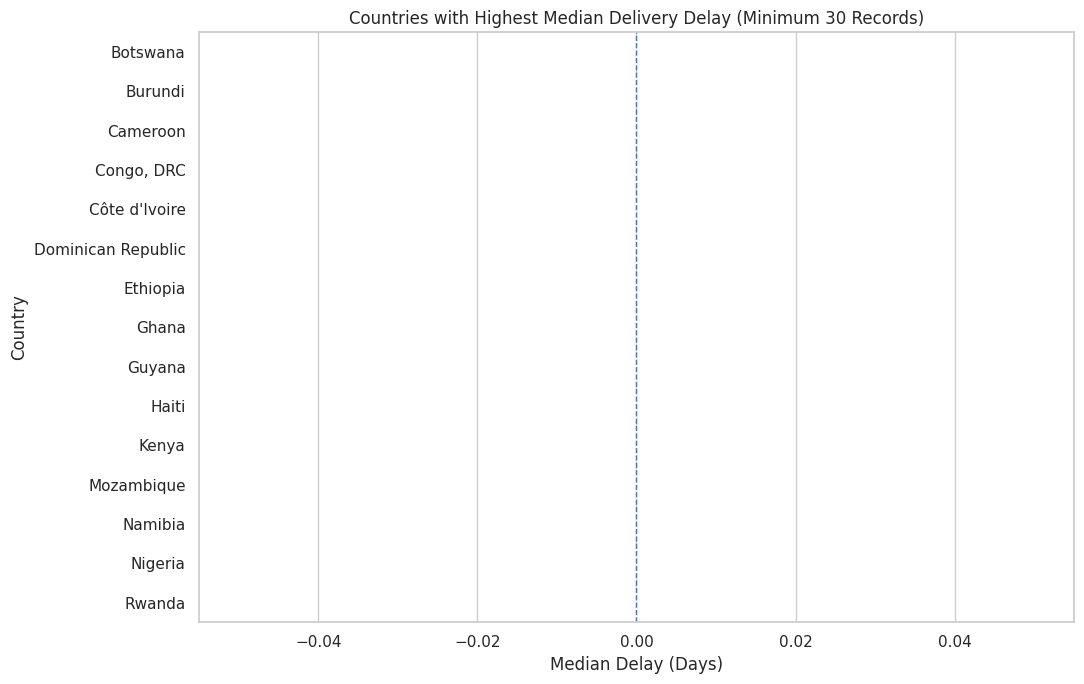

In [ ]:
country_delay = data.dropna(subset=["Delivery_Delay_Days", "Country"])
country_summary = country_delay.groupby("Country")["Delivery_Delay_Days"].agg(
    Records="count", Median_Delay="median", Mean_Delay="mean"
)
# Focus on countries with at least 30 evaluable records to reduce unstable small-sample comparisons.
country_summary_filtered = country_summary[country_summary["Records"] >= 30].sort_values("Median_Delay", ascending=False)
display(country_summary_filtered.head(15).round(2))
if not country_summary_filtered.empty:
    plot_data = country_summary_filtered.head(15).sort_values("Median_Delay")
    plt.figure(figsize=(11, 7))
    sns.barplot(data=plot_data.reset_index(), y="Country", x="Median_Delay")
    plt.axvline(0, linestyle="--", linewidth=1)
    plt.title("Countries with Highest Median Delivery Delay (Minimum 30 Records)")
    plt.xlabel("Median Delay (Days)")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()

**Why this chart?** A horizontal bar chart ranks country-level median delays and keeps country labels readable.  
**What to observe:** Countries with higher median delays among groups meeting the minimum record threshold.  
**Business relevance:** Supports targeted review of destination-specific processes. This is not a country performance ranking unless data coverage and operational context are comparable.

**Interpretation – Delivery Delay by Destination Country**

- The analysis considered only countries with at least 30 evaluable shipment records.
- The displayed top 15 countries all had a median delivery delay of 0 days.
- Mean delays varied across countries.
- Congo, DRC showed a mean delay of 11.24 days, while Kenya showed a mean delay of 0.89 days.
- Guyana showed a mean delay of -17.82 days.

**Business Insight:** Although the median delay was zero for all displayed countries, differences in mean delay suggest variation in delivery patterns. Countries with higher average delays should be investigated further, considering shipment volume and extreme observations.

### 7.7 Freight cost by shipment mode

,Records,Median_Freight,Mean_Freight
Shipment Mode,,,
Air Charter,577,11492.86,14727.51
Ocean,326,8156.9,8109.59
Truck,1840,2414.39,5387.83
Air,5589,2336.46,5888.49


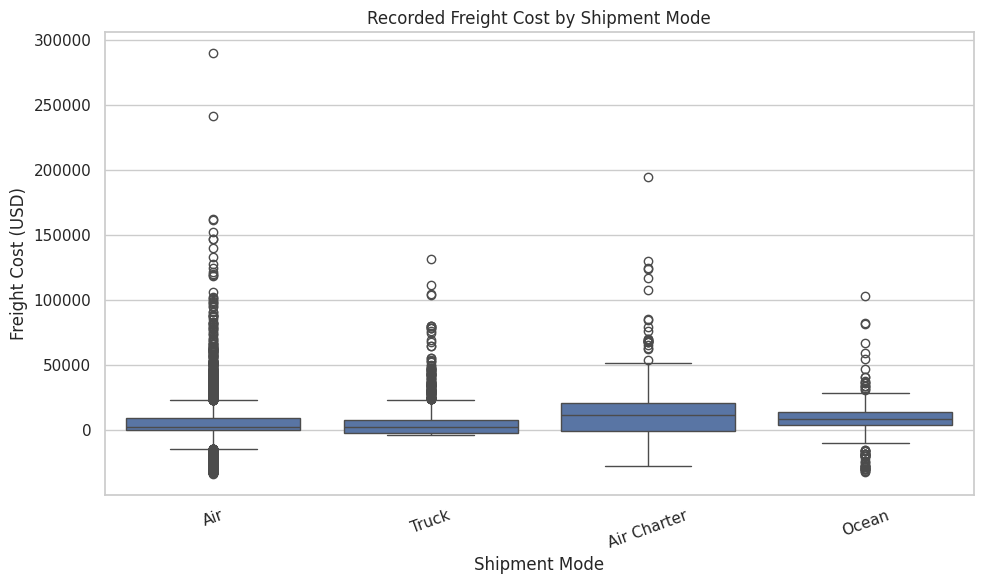

In [ ]:
freight_mode = data.dropna(subset=["Freight_Cost_USD_numeric", "Shipment Mode"])
freight_mode_summary = freight_mode.groupby("Shipment Mode")["Freight_Cost_USD_numeric"].agg(
    Records="count", Median_Freight="median", Mean_Freight="mean"
).sort_values("Median_Freight", ascending=False)
display(freight_mode_summary.round(2))
if not freight_mode.empty:
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=freight_mode, x="Shipment Mode", y="Freight_Cost_USD_numeric")
    plt.title("Recorded Freight Cost by Shipment Mode")
    plt.xlabel("Shipment Mode")
    plt.ylabel("Freight Cost (USD)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

**Why this chart?** Box plots compare freight-cost distributions and highlight variation and extreme recorded costs.  
**What to observe:** Differences in median and spread, while remembering that only numeric freight entries are included.  
**Business relevance:** Can guide further cost review, but freight costs should not be compared without considering shipment size, weight, route, and accounting labels.

** Interpretation – Freight Cost by Shipment Mode**

- Air Charter had the highest median recorded freight cost at approximately USD 11,492.86.
- Ocean had a median freight cost of approximately USD 8,156.90.
- Truck had a median freight cost of approximately USD 2,414.39.
- Air had a median freight cost of approximately USD 2,336.46.
- The average freight cost was higher than the median for Air and Truck, indicating the influence of high-cost observations.

**Business Insight:** Recorded freight costs varied across shipment modes. Air Charter and Ocean showed higher median costs than Air and Truck. These values should not be treated as direct evidence that one mode is more expensive for equivalent shipments because route, distance, weight, and service conditions are not controlled.

### 7.8 Freight cost and shipment weight

Records available for positive weight/freight comparison: 6174
Pearson correlation (descriptive): 0.232


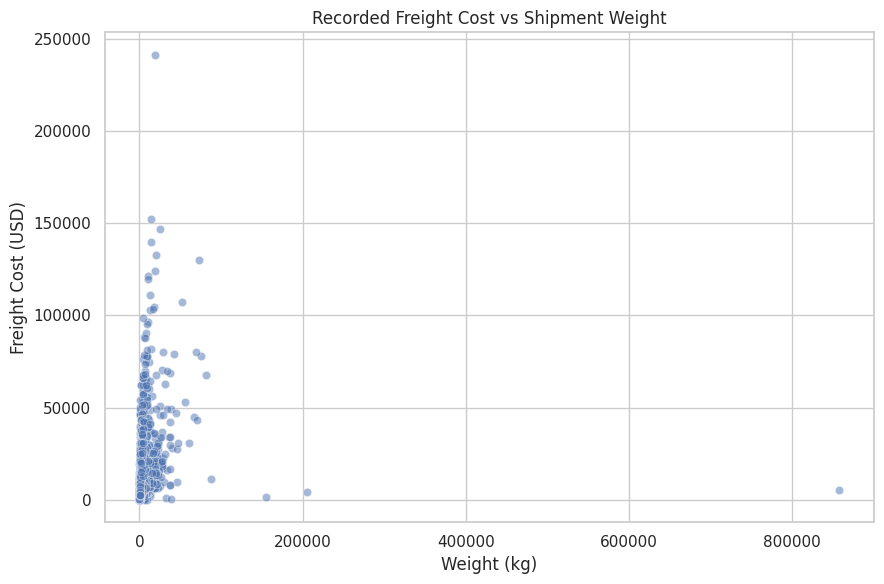

In [ ]:
weight_freight = data.dropna(subset=["Weight_kg_numeric", "Freight_Cost_USD_numeric"])
# Exclude non-positive values for log-scale visualization and correlation.
weight_freight_positive = weight_freight[
    (weight_freight["Weight_kg_numeric"] > 0) &
    (weight_freight["Freight_Cost_USD_numeric"] > 0)
]
print("Records available for positive weight/freight comparison:", len(weight_freight_positive))
if len(weight_freight_positive) >= 2:
    corr = weight_freight_positive[["Weight_kg_numeric", "Freight_Cost_USD_numeric"]].corr().iloc[0, 1]
    print(f"Pearson correlation (descriptive): {corr:.3f}")
    sample_plot = weight_freight_positive.sample(
        min(3000, len(weight_freight_positive)), random_state=42
    )
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=sample_plot, x="Weight_kg_numeric", y="Freight_Cost_USD_numeric",
        alpha=0.5
    )
    plt.title("Recorded Freight Cost vs Shipment Weight")
    plt.xlabel("Weight (kg)")
    plt.ylabel("Freight Cost (USD)")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough valid observations for correlation/scatter analysis.")

**Why this chart?** A scatter plot reveals whether recorded freight cost tends to move with shipment weight and whether there are unusual observations.  
**What to observe:** Direction, strength, clusters, and outliers.  
**Business relevance:** Helps assess whether weight is a useful factor for freight-cost analysis. Correlation is not causation and may be affected by route and shipment mode.

**Interpretation – Freight Cost and Shipment Weight**

- A total of 6,174 records had positive numeric values for both shipment weight and freight cost.
- The Pearson correlation coefficient was 0.232.
- This indicates a weak positive linear relationship between shipment weight and freight cost.
- The scatter plot shows variation in freight costs across different shipment weights.

**Business Insight:** Shipment weight may be one factor associated with freight cost, but the weak correlation indicates that other factors may also influence costs. Route distance, shipment mode, and service level should be considered in further analysis.

### 7.9 Delivery delay by fulfillment method

,Records,Median_Delay,Mean_Delay
Fulfill Via,,,
Direct Drop,4920,0.0,-3.54
From RDC,5404,0.0,-8.28


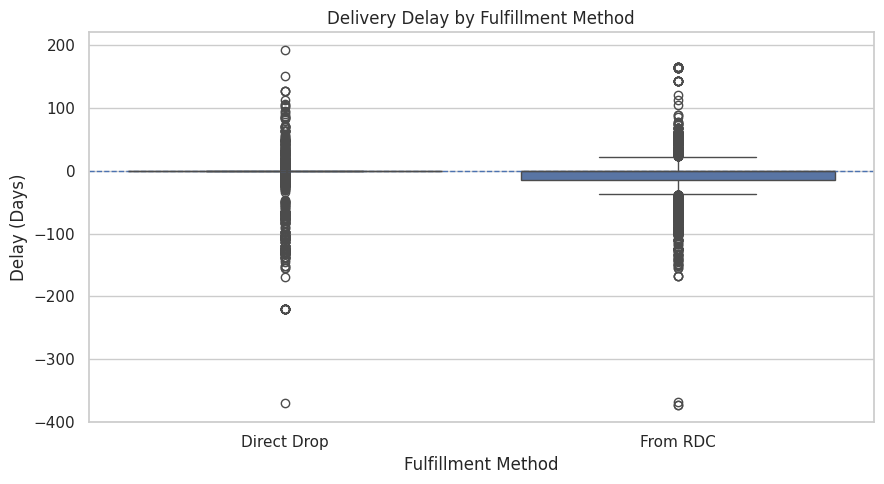

In [ ]:
fulfill_delay = data.dropna(subset=["Delivery_Delay_Days", "Fulfill Via"])
fulfill_summary = fulfill_delay.groupby("Fulfill Via")["Delivery_Delay_Days"].agg(
    Records="count", Median_Delay="median", Mean_Delay="mean"
)
display(fulfill_summary.round(2))
if not fulfill_delay.empty:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=fulfill_delay, x="Fulfill Via", y="Delivery_Delay_Days")
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.title("Delivery Delay by Fulfillment Method")
    plt.xlabel("Fulfillment Method")
    plt.ylabel("Delay (Days)")
    plt.tight_layout()
    plt.show()

**Why this chart?** A box plot compares delivery-delay distributions for the available fulfillment categories.  
**What to observe:** Differences in median delay and spread, together with group sizes.  
**Business relevance:** May identify whether RDC and Direct Drop flows merit separate process reviews.

**Interpretation – Delivery Delay by Fulfillment Method**

- Direct Drop included 4,920 records, with an average delay of -3.54 days.
- From RDC included 5,404 records, with an average delay of -8.28 days.
- Both fulfillment methods had a median delay of 0 days.
- From RDC showed a more negative average delay than Direct Drop.

**Business Insight:** Both fulfillment methods had the same median delivery delay. The difference in average delay suggests variation in their delivery patterns, but further investigation is needed before concluding that one method performs better.

### 7.10 Monthly delivery trend

,Delivery_Month,Records,Median_Delay,Mean_Delay
0,2006-05-01,2,0.0,0.0
1,2006-06-01,2,0.0,0.0
2,2006-07-01,3,0.0,-23.0
3,2006-08-01,6,0.0,0.0
4,2006-09-01,18,0.0,0.0


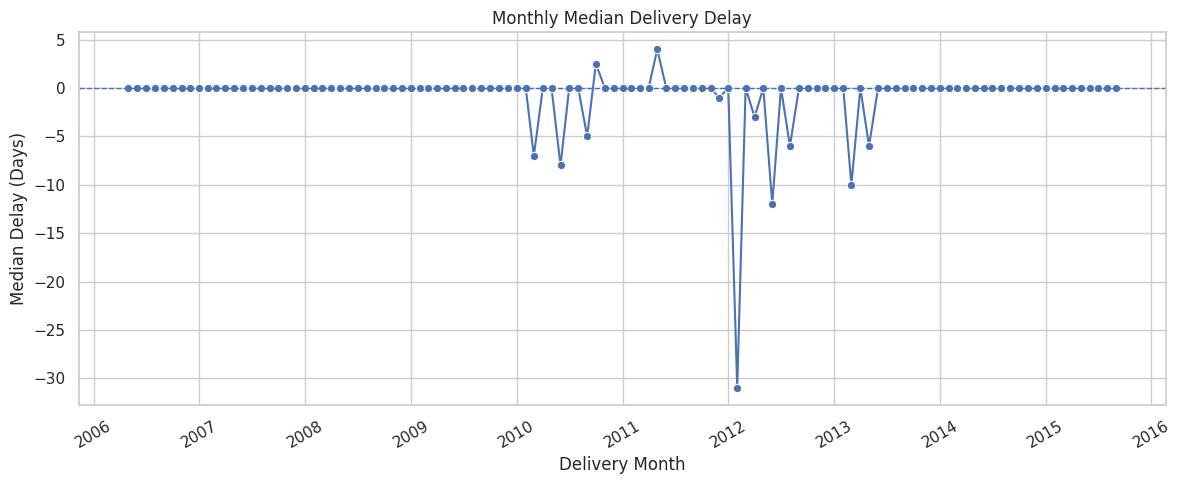

In [ ]:
monthly = data.dropna(subset=["Delivered to Client Date Parsed", "Delivery_Delay_Days"]).copy()
if not monthly.empty:
    monthly["Delivery_Month"] = monthly["Delivered to Client Date Parsed"].dt.to_period("M").dt.to_timestamp()
    monthly_trend = monthly.groupby("Delivery_Month")["Delivery_Delay_Days"].agg(
        Records="count", Median_Delay="median", Mean_Delay="mean"
    ).reset_index()
    display(monthly_trend.head())
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=monthly_trend, x="Delivery_Month", y="Median_Delay", marker="o")
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.title("Monthly Median Delivery Delay")
    plt.xlabel("Delivery Month")
    plt.ylabel("Median Delay (Days)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("No valid delivery dates and delays available for monthly trend analysis.")

**Why this chart?** A line chart is suitable for examining changes over time.  
**What to observe:** Months with higher or lower median delay and months with very low record counts.  
**Business relevance:** Helps identify periods for deeper investigation, but seasonality or operational causes require additional data.

**Interpretation – Monthly Delivery Trend**

- The analysis groups evaluated shipments by their actual delivery month.
- Monthly median and average delays are calculated to observe changes in delivery performance over time.
- The record count for each month is also considered to understand the volume behind each monthly result.
- Monthly shipment volumes vary, so months with very few records should be interpreted cautiously.

**Business Insight:** Monthly monitoring can help identify changes in delivery performance and possible periods of operational difficulty. Further investigation should focus on months with consistently higher median delays and sufficient shipment volumes.

## 8. Statistical Checks

### 8.1 Delivery status proportions among evaluable records

In [ ]:
evaluated = data[data["Delivery_Delay_Days"].notna()]
if len(evaluated):
    status_pct = (evaluated["Delivery_Status"].value_counts(normalize=True) * 100).round(2)
    display(status_pct.to_frame("Percent of Evaluable Deliveries"))
    print("Evaluable deliveries:", len(evaluated))
else:
    print("No evaluable delivery records.")

,Percent of Evaluable Deliveries
Delivery_Status,
On Time,61.26
Early,27.26
Late,11.49


Evaluable deliveries: 10324


### 8.2 Compare delay groups with a non-parametric test (optional)

In [ ]:
# Kruskal-Wallis test compares delay distributions across shipment modes.
# It is used here as a descriptive group-comparison check; it does not establish causality.
try:
    from scipy.stats import kruskal
    groups = [
        grp["Delivery_Delay_Days"].dropna().values
        for _, grp in data.dropna(subset=["Shipment Mode"]).groupby("Shipment Mode")
    ]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) >= 2:
        statistic, p_value = kruskal(*groups)
        print(f"Kruskal-Wallis statistic: {statistic:.3f}")
        print(f"p-value: {p_value:.6g}")
        print("Interpretation: A small p-value suggests at least one shipment-mode delay distribution differs; inspect group sizes and practical effect before drawing business conclusions.")
    else:
        print("At least two non-empty shipment-mode groups are required.")
except ImportError:
    print("SciPy is unavailable in this environment; skip this optional test.")

Kruskal-Wallis statistic: 613.755
p-value: 1.05065e-132
Interpretation: A small p-value suggests at least one shipment-mode delay distribution differs; inspect group sizes and practical effect before drawing business conclusions.


## 9. Key Findings and Business Interpretation

In [ ]:
# Generate concise metrics from the current dataset for use in the conclusion.
total_records = len(data)
evaluable_count = data["Delivery_Delay_Days"].notna().sum()
late_count = (data["Delivery_Status"] == "Late").sum()
on_time_count = (data["Delivery_Status"] == "On Time").sum()
early_count = (data["Delivery_Status"] == "Early").sum()

print(f"Total records: {total_records:,}")
print(f"Records with evaluable delivery delay: {evaluable_count:,} ({evaluable_count/total_records:.1%})")
if evaluable_count:
    print(f"Late: {late_count:,} ({late_count/evaluable_count:.1%} of evaluable)")
    print(f"On time: {on_time_count:,} ({on_time_count/evaluable_count:.1%} of evaluable)")
    print(f"Early: {early_count:,} ({early_count/evaluable_count:.1%} of evaluable)")
    print(f"Median delay: {data['Delivery_Delay_Days'].median():.1f} days")
print(f"Numeric freight records: {data['Freight_Cost_USD_numeric'].notna().sum():,}")
print(f"Numeric weight records: {data['Weight_kg_numeric'].notna().sum():,}")

Total records: 10,324
Records with evaluable delivery delay: 10,324 (100.0%)
Late: 1,186 (11.5% of evaluable)
On time: 6,324 (61.3% of evaluable)
Early: 2,814 (27.3% of evaluable)
Median delay: 0.0 days
Numeric freight records: 8,643
Numeric weight records: 8,817


### Business interpretation - Key Findings


1. **Delivery Reliability:** Out of 10,324 evaluated deliveries, 61.26% were delivered on time, 27.26% early, and 11.49% late. Delivery-delay evaluation coverage was 100% in the processed dataset.

2. **Shipment Mode:** Ocean shipments showed a positive average delay of 5.87 days, while Air, Air Charter, and Truck showed negative average delays. Median delay was 0 days for Air, Ocean, and Truck, and -13 days for Air Charter. These are observed differences, not proof that shipment mode causes delays.

3. **Product Group:** ARV accounted for the largest number of records (8,550), followed by HRDT (1,728). The remaining groups had very small record counts.

4. **Freight Costs:** Numeric freight values were available for 8,643 records. Descriptive entries such as "Freight Included in Commodity Cost" and "Invoiced Separately" were not treated as numeric costs.

5. **Data Quality:** Missing values were found in Dosage (1,736), Shipment Mode (360), and Line Item Insurance (USD) (287). Weight and freight columns also contained descriptive text labels, which were excluded from numeric calculations.


## 10. Actionable Recommendations

Based on the EDA findings, the following actions are recommended to improve logistics operations and delivery performance:

1. **Investigate Late Deliveries:** Analyze the 1,186 late shipments (11.49%) using purchase order and ASN/DN identifiers to identify recurring reasons for delays.

2. **Review Ocean Shipments:** Ocean shipments showed an average delivery delay of 5.87 days. Investigate their transit schedules, delivery routes, and operational constraints, while considering the shipment volume and median delay.

3. **Monitor Delivery Performance:** Track on-time, early, and late delivery percentages regularly. Monitor both average and median delay along with shipment volume to identify meaningful changes.

4. **Improve Country-Level Analysis:** Compare delivery performance across destination countries using sufficient shipment records. Investigate countries with consistently higher average delays rather than relying only on median values.

5. **Improve Data Quality:** Standardize date formats and ensure important fields such as shipment mode, dosage, and insurance cost are recorded consistently.

6. **Standardize Freight and Weight Records:** Store numeric freight costs and shipment weights separately from descriptive accounting notes to support accurate cost analysis.

7. **Improve Logistics Planning:** Consider shipment mode, destination, shipment volume, and historical delivery patterns when planning future shipments.

## 11. Challenges and Limitations

The analysis faced the following data and analytical limitations:

- Some date columns contained process labels or placeholders instead of valid dates, particularly in purchase-request and vendor-order date fields.
- Freight and weight columns contained both numeric values and descriptive text entries, requiring separate numeric extraction.
- Although all 10,324 records had valid scheduled and delivered dates for this analysis, other date fields had incomplete or unparseable entries.
- Numeric freight and weight analysis was limited to records with extractable numeric values.
- Freight-cost comparisons were not adjusted for route distance, package dimensions, shipment complexity, or service level.
- Shipment-mode and fulfillment-method comparisons show statistical associations, not proof of causation.
- Product groups had highly uneven record counts, with ARV representing the majority of the dataset.
- The dataset did not contain every operational factor required to explain the reasons behind delivery delays.


## 12. Conclusion

This Exploratory Data Analysis of the FedEx Logistics Supply Chain Delivery History dataset examined 10,324 shipment records across 33 columns to understand delivery performance, shipment patterns, product distribution, and logistics costs.

The analysis found that 61.26% of deliveries were completed on time, 27.26% were early, and 11.49% were late. Ocean shipments showed an average positive delivery delay of 5.87 days, indicating an area that deserves further investigation. ARV was the largest product group, accounting for 8,550 records.

The project also identified data-quality challenges, including missing values, inconsistent date entries, and descriptive text in freight and weight fields. These limitations were considered during data cleaning and analysis.

Overall, this project demonstrates how Python, Pandas, NumPy, Matplotlib, and Seaborn can be used to transform raw logistics data into meaningful business insights. The findings can help organizations monitor delivery performance, investigate delays, improve data quality, and make better logistics-planning decisions.


## 13. Future Scope

The project can be extended in the following ways:

1. **Power BI Dashboard:** Develop an interactive dashboard to monitor delivery status, shipment delays, country-level performance, shipment modes, and freight costs.

2. **Advanced Delay Analysis:** Include route distance, planned transit time, carrier information, service levels, and disruption events to understand delivery delays more accurately.

3. **Predictive Analytics:** Build a machine learning model to predict the risk of late delivery after validating data quality and defining a reliable prediction target.

4. **Automated Alerts:** Develop an alert system to identify shipments that may exceed their scheduled delivery dates.

5. **Improved Data Management:** Establish standardized data-entry rules for dates, freight costs, shipment weights, and shipment classifications.

6. **Time-Based Monitoring:** Analyze monthly and yearly delivery trends to identify recurring seasonal patterns and changes in logistics performance.